# Fase 3 — Segmentação e perfil operacional

**Apenas train, ao corte de 25/06/2024. Eval congelado.**

ABC do produto + XYZ da série + exposição/possível censura permanecem separados. Não há forecasting ou política de reposição. As nove figuras consomem outputs de `python scripts/build_segmentation.py`. Regras e tabelas completas em `docs/segmentation_report.md`.

No backtesting futuro, recalcular ABC/XYZ/quantis em cada origem; este retrato final não pode ser reutilizado retrospectivamente.

In [1]:
%matplotlib inline
from pathlib import Path
import sys
root = Path.cwd()
if not (root / 'src').is_dir():
    root = root.parent
sys.path.insert(0, str(root))
import matplotlib.pyplot as plt
from IPython.display import display
from src.reporting.segmentation_plots import load_outputs, PLOTS, save_figure
data = load_outputs(root)
assert data['summary']['source_split'] == 'train'
print(f"{data['summary']['n_products']} produtos; {data['summary']['n_series']:,} séries; corte {data['summary']['as_of']}")

865 produtos; 50,000 séries; corte 2024-06-25


## 01. ABC por contribuição

A/B/C é definido por produto, pelo acumulado antes do item. O item que cruza 80%/95% completa a classe.

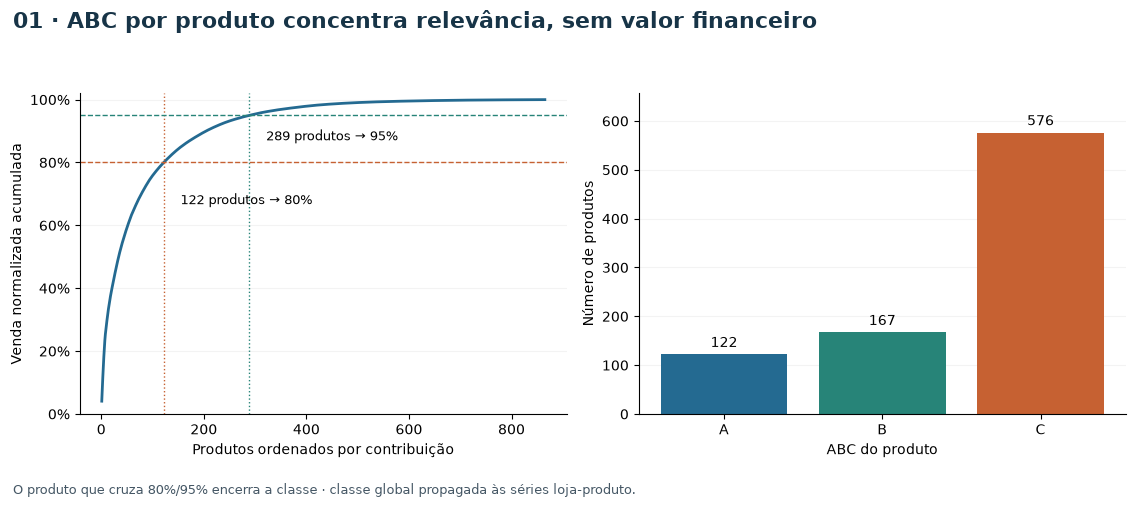

In [2]:
fig = PLOTS[0](data)
save_figure(fig, 1, root)
display(fig)
plt.close(fig)

## 02. Redundância das métricas

Correlação não prova equivalência. A escolha mínima separa variação entre semanas da estabilidade da forma por weekday.

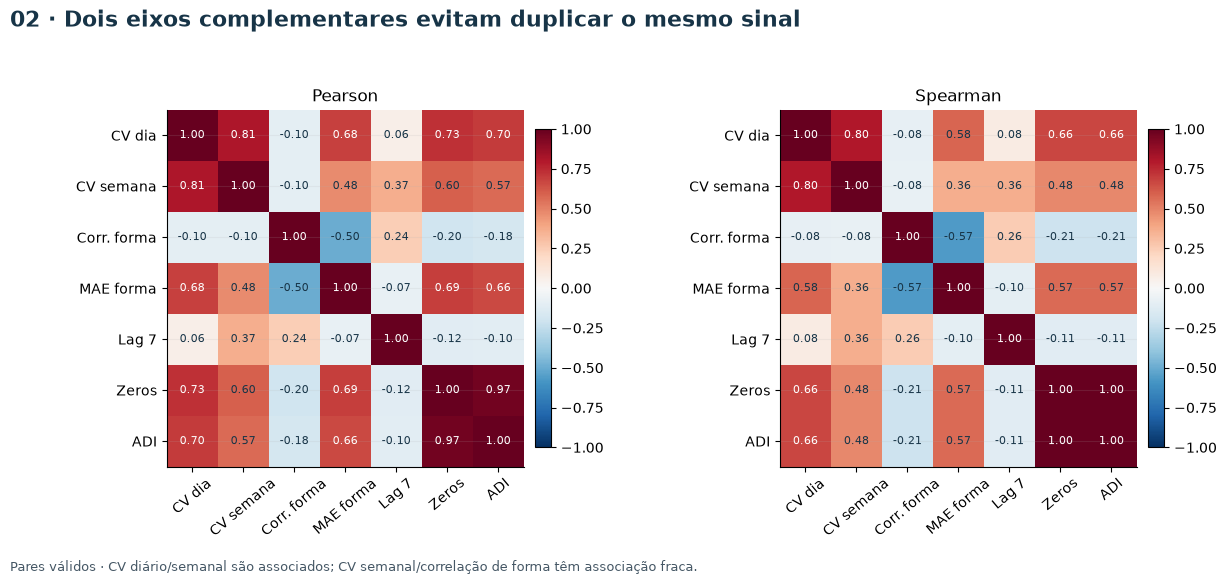

In [3]:
fig = PLOTS[1](data)
save_figure(fig, 2, root)
display(fig)
plt.close(fig)

## 03. Regras XYZ

Linhas mostram limites calculados em train. Z tem precedência, X exige ambos os critérios favoráveis e Y reúne os demais. Quatro indefinidos têm fallback explícito.

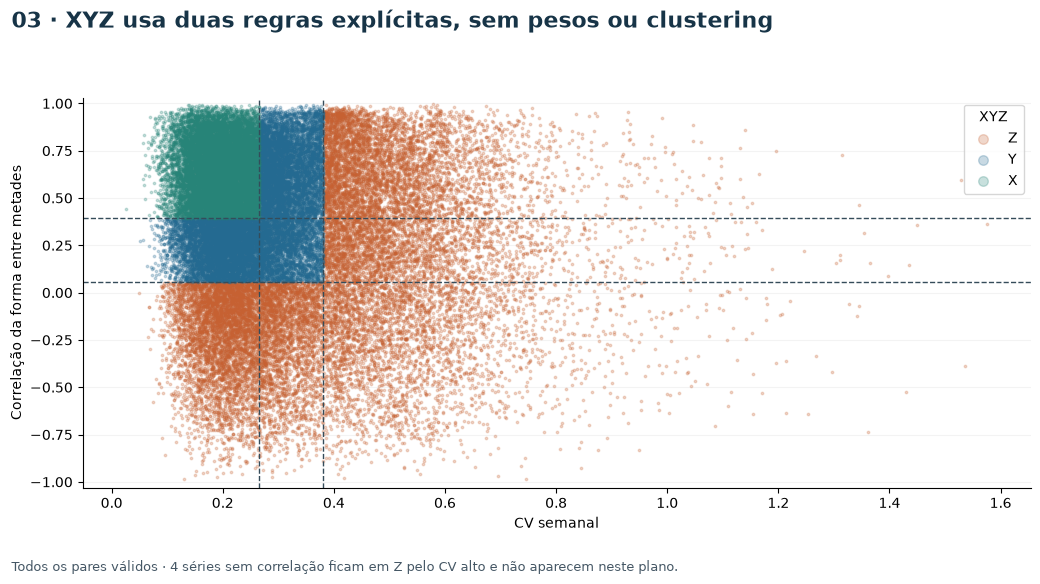

In [4]:
fig = PLOTS[2](data)
save_figure(fig, 3, root)
display(fig)
plt.close(fig)

## 04. Diferenças entre classes

A separação nas métricas da regra é esperada por construção. Lag 7 é evidência complementar e não confirma uma ordem de previsibilidade.

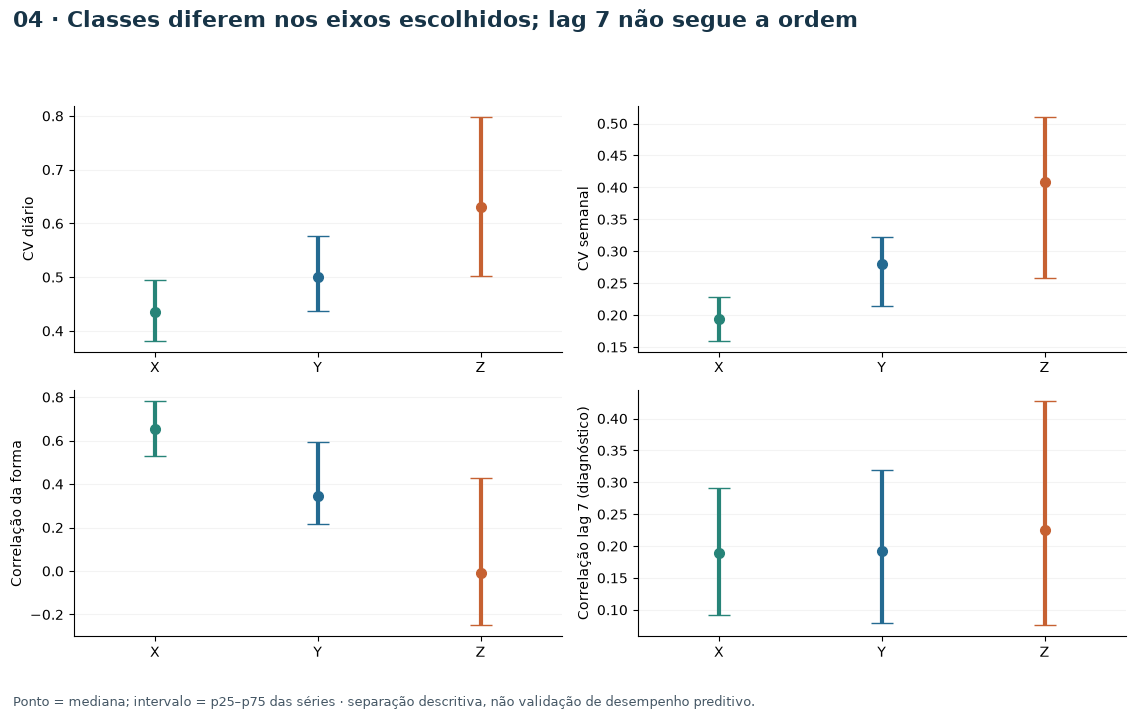

In [5]:
fig = PLOTS[3](data)
save_figure(fig, 4, root)
display(fig)
plt.close(fig)

## 05. Tamanhos e sensibilidade

Quatro regras transparentes foram comparadas. A escolha não força quantidades iguais nem usa erro de forecast.

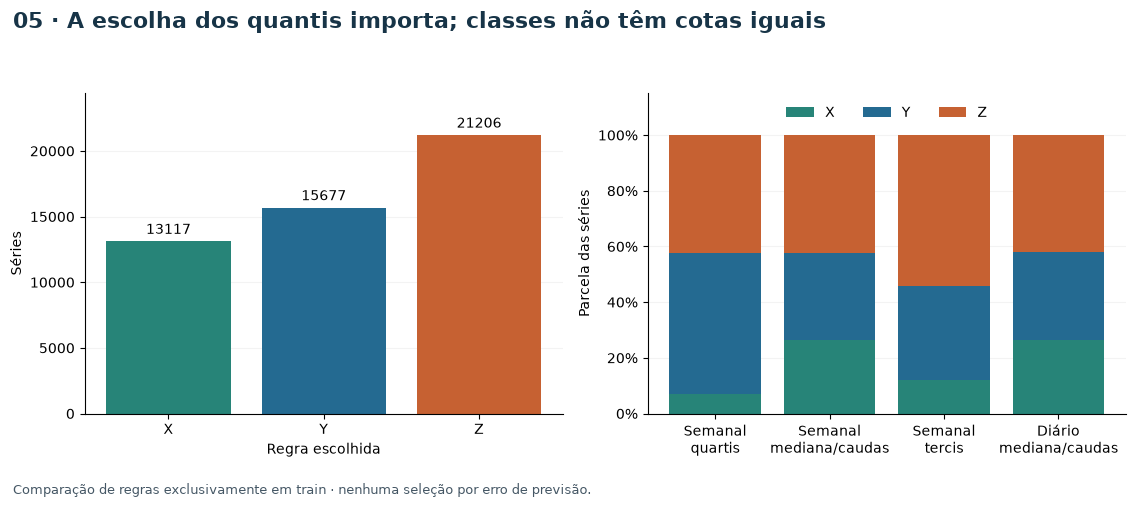

In [6]:
fig = PLOTS[4](data)
save_figure(fig, 5, root)
display(fig)
plt.close(fig)

## 06. Exposição à ruptura

Exposição é frequência relativa, separada de XYZ. LOW não significa disponibilidade adequada durante todo o dia.

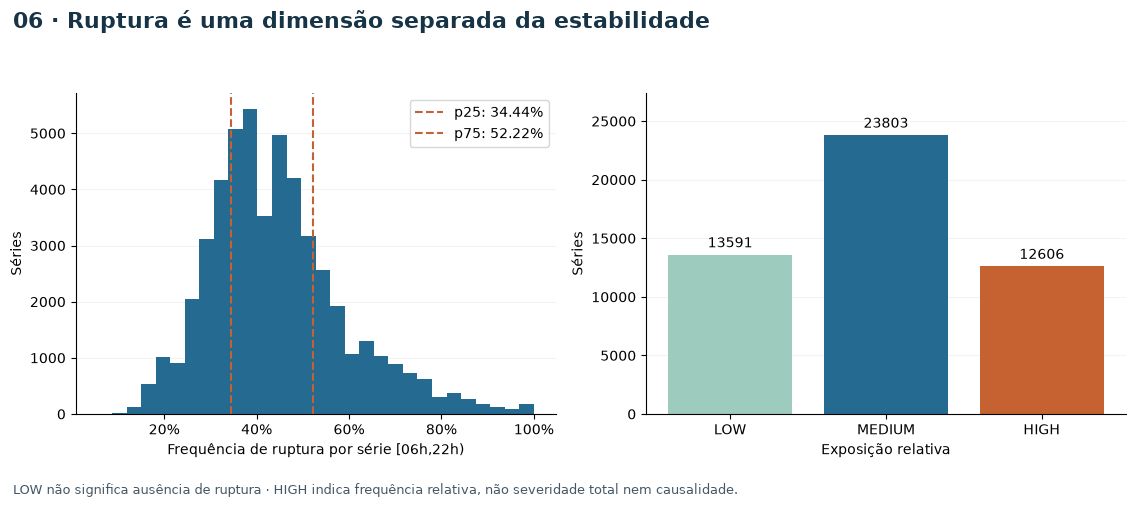

In [7]:
fig = PLOTS[5](data)
save_figure(fig, 6, root)
display(fig)
plt.close(fig)

## 07. ABC × XYZ

Classes de produto são propagadas às séries. Contagens de produtos nas células não são aditivas; séries e vendas são.

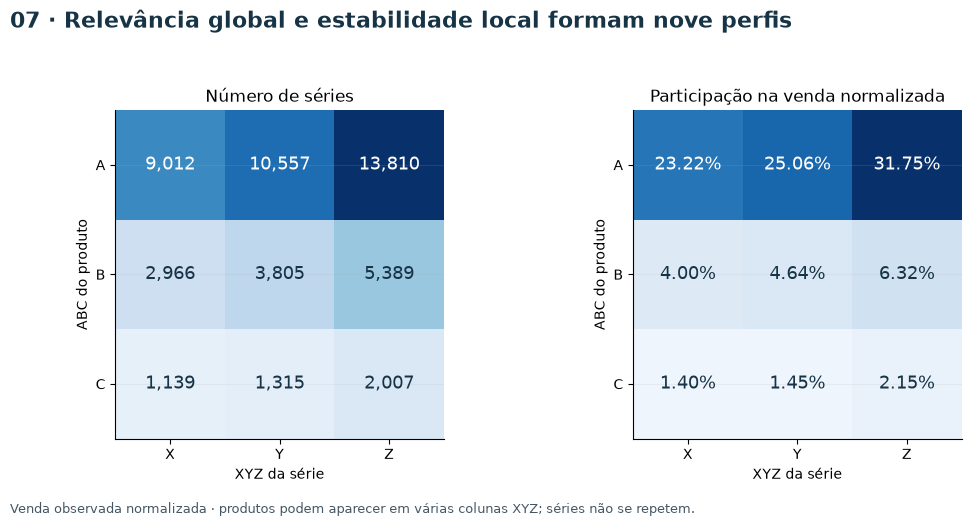

In [8]:
fig = PLOTS[6](data)
save_figure(fig, 7, root)
display(fig)
plt.close(fig)

## 08. Disponibilidade dentro dos perfis

A flag marca alta exposição à possível censura. Ela não mede demanda perdida nem substitui as demais dimensões.

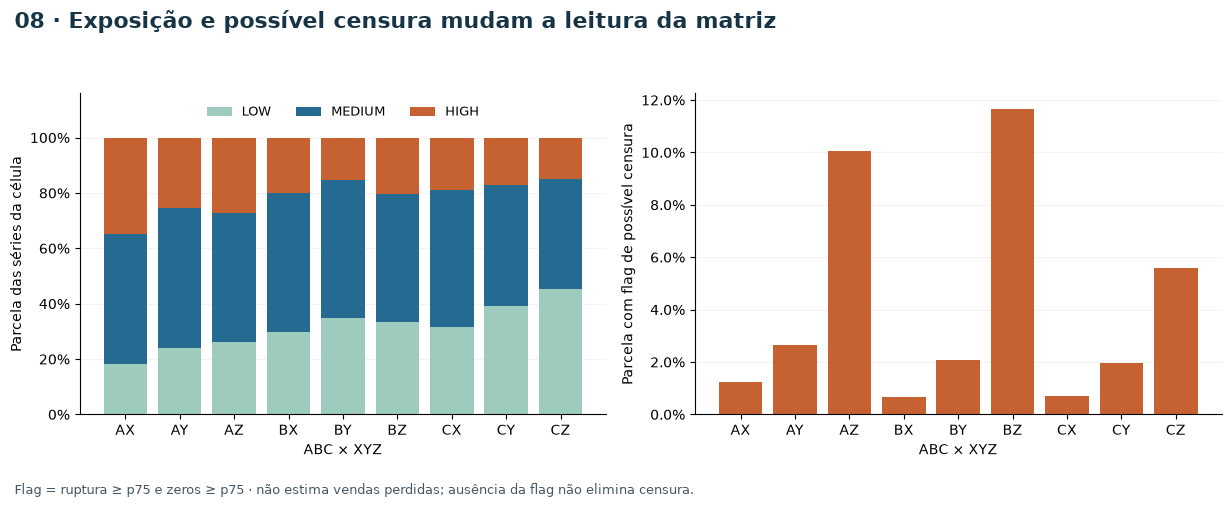

In [9]:
fig = PLOTS[7](data)
save_figure(fig, 8, root)
display(fig)
plt.close(fig)

## 09. Exemplos por regras

Filtros e desempates ficam no pipeline. Os exemplos próximos da mediana usam apenas distância no CV semanal, sem score composto.

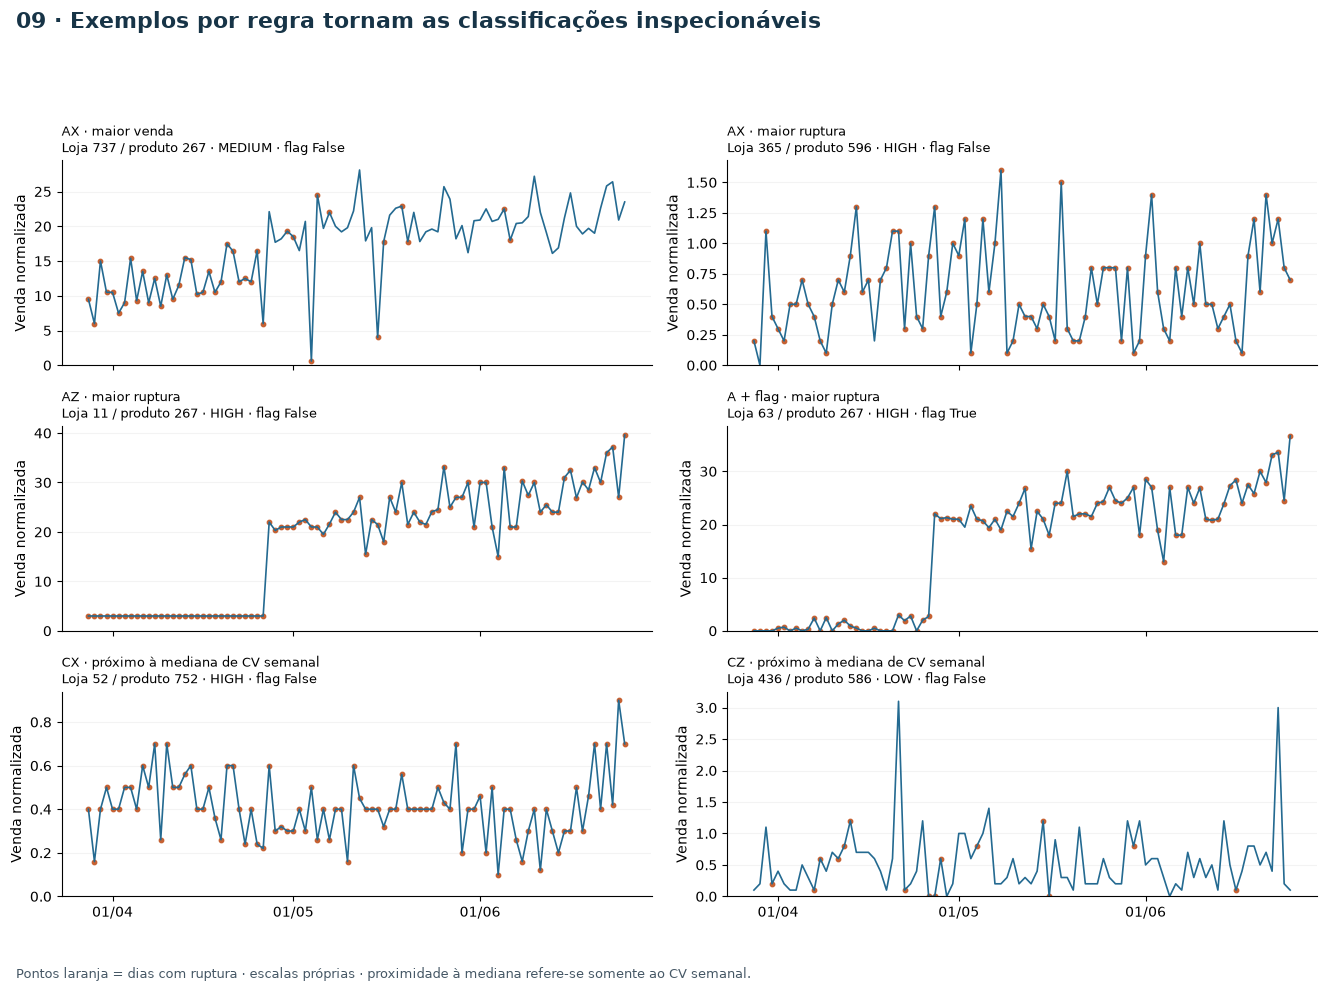

In [10]:
fig = PLOTS[8](data)
save_figure(fig, 9, root)
display(fig)
plt.close(fig)